Original bits:   [1 0 1 1 0 0 1 0]
BPSK symbols:    [-1  1 -1 -1  1  1 -1  1]


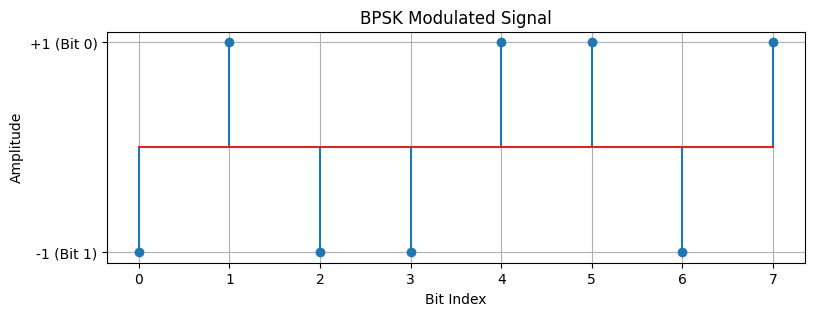

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Original binary message
bits = np.array([1, 0, 1, 1, 0, 0, 1, 0])

# BPSK modulation: 0 becomes +1, 1 becomes -1
symbols = 1 - 2 * bits

print("Original bits:  ", bits)
print("BPSK symbols:   ", symbols)

# Plot the transmitted symbols
plt.figure(figsize=(9, 3))
plt.stem(range(len(symbols)), symbols)
plt.title("BPSK Modulated Signal")
plt.xlabel("Bit Index")
plt.ylabel("Amplitude")
plt.yticks([-1, 1], ["-1 (Bit 1)", "+1 (Bit 0)"])
plt.grid(True)
plt.show()


Original bits:   [1 0 1 1 0 0 1 0]
Received signal: [-0.55  1.3  -0.82 -0.51  0.41  1.55 -1.22  1.31]
Recovered bits:  [1 0 1 1 0 0 1 0]
Number of bit errors: 0
Bit Error Rate (BER): 0.0


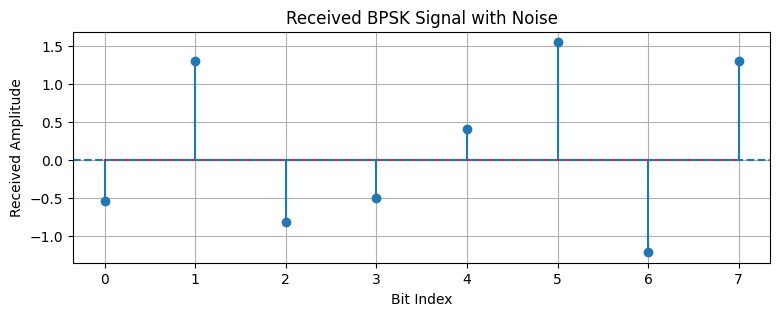

In [2]:

# Set the signal-to-noise ratio
snr_db = 3

# Convert SNR from decibels to a linear value
snr_linear = 10 ** (snr_db / 10)

# Generate Gaussian noise
noise_std = np.sqrt(1 / (2 * snr_linear))
noise = np.random.normal(0, noise_std, len(symbols))

# Signal received through the noisy channel
received = symbols + noise

# BPSK demodulation: positive means bit 0, negative means bit 1
recovered_bits = (received < 0).astype(int)

print("Original bits:  ", bits)
print("Received signal:", np.round(received, 2))
print("Recovered bits: ", recovered_bits)

errors = np.sum(bits != recovered_bits)
ber = errors / len(bits)

print("Number of bit errors:", errors)
print("Bit Error Rate (BER):", ber)

plt.figure(figsize=(9, 3))
plt.stem(range(len(received)), received)
plt.axhline(0, linestyle="--")
plt.title("Received BPSK Signal with Noise")
plt.xlabel("Bit Index")
plt.ylabel("Received Amplitude")
plt.grid(True)
plt.show()


SNR =  0 dB | Errors = 23668 | Simulated BER = 0.078893 | Theoretical BER = 0.078650
SNR =  1 dB | Errors = 16826 | Simulated BER = 0.056087 | Theoretical BER = 0.056282
SNR =  2 dB | Errors = 11267 | Simulated BER = 0.037557 | Theoretical BER = 0.037506
SNR =  3 dB | Errors =  6853 | Simulated BER = 0.022843 | Theoretical BER = 0.022878
SNR =  4 dB | Errors =  3761 | Simulated BER = 0.012537 | Theoretical BER = 0.012501
SNR =  5 dB | Errors =  1841 | Simulated BER = 0.006137 | Theoretical BER = 0.005954
SNR =  6 dB | Errors =   732 | Simulated BER = 0.002440 | Theoretical BER = 0.002388
SNR =  7 dB | Errors =   244 | Simulated BER = 0.000813 | Theoretical BER = 0.000773
SNR =  8 dB | Errors =    52 | Simulated BER = 0.000173 | Theoretical BER = 0.000191


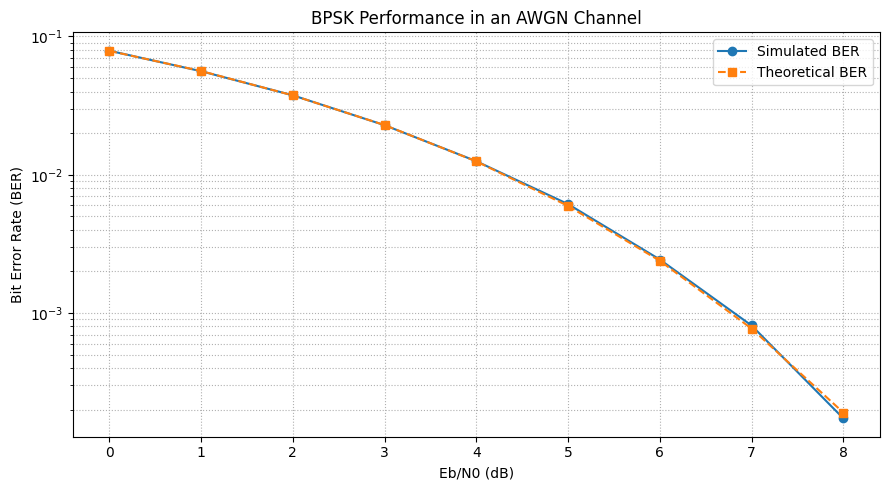

In [3]:

import numpy as np
import matplotlib.pyplot as plt
from math import erfc, sqrt

# ------------------------------------
# SMART DIGITAL COMMUNICATION ANALYZER
# ------------------------------------

np.random.seed(42)  # Reproducible results

# 1. Generate binary data
N = 300_000
bits = np.random.randint(0, 2, N)

# 2. BPSK modulation: 0 -> +1, 1 -> -1
tx = 1 - 2 * bits

# 3. Test different SNR values
snr_db_values = np.arange(0, 9, 1)

simulated_ber = []
theoretical_ber = []

for snr_db in snr_db_values:

    # Convert dB to linear Eb/N0
    eb_n0 = 10 ** (snr_db / 10)

    # 4. Add AWGN noise
    noise_std = sqrt(1 / (2 * eb_n0))
    noise = np.random.normal(0, noise_std, N)
    rx = tx + noise

    # 5. Demodulate at the zero threshold
    recovered = (rx < 0).astype(int)

    # 6. Calculate errors and BER
    errors = np.sum(bits != recovered)
    ber = errors / N

    simulated_ber.append(ber)

    # Theoretical BER for coherent BPSK in AWGN
    theory = 0.5 * erfc(sqrt(eb_n0))
    theoretical_ber.append(theory)

    print(
        f"SNR = {snr_db:2d} dB | "
        f"Errors = {errors:5d} | "
        f"Simulated BER = {ber:.6f} | "
        f"Theoretical BER = {theory:.6f}"
    )

# 7. Plot performance curves
plt.figure(figsize=(9, 5))

plt.semilogy(
    snr_db_values, simulated_ber,
    "o-", label="Simulated BER"
)

plt.semilogy(
    snr_db_values, theoretical_ber,
    "s--", label="Theoretical BER"
)

plt.title("BPSK Performance in an AWGN Channel")
plt.xlabel("Eb/N0 (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.grid(True, which="both", linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()
